In [1]:
# Importing necessary libraries for data manipulation and visualization
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Importing preprocessing and model classes from sklearn
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, MinMaxScaler
from sklearn.linear_model import LogisticRegression, Lasso, Ridge

# Importing metrics for model evaluation
from sklearn.metrics import mean_squared_error, confusion_matrix, accuracy_score
# Importing train_test_split for splitting the dataset into training and testing sets
from sklearn.model_selection import train_test_split
# Importing RandomForestClassifier for classification tasks
from sklearn.ensemble import RandomForestClassifier

# Suppressing warnings for cleaner output
import warnings
warnings.filterwarnings("ignore")

# Defining a class to hold color codes for terminal output
class color:
   PURPLE = '\033[95m'      # Purple color code
   CYAN = '\033[96m'        # Cyan color code
   DARKCYAN = '\033[36m'    # Dark Cyan color code
   BLUE = '\033[94m'        # Blue color code
   GREEN = '\033[92m'       # Green color code
   YELLOW = '\033[93m'      # Yellow color code
   RED = '\033[91m'         # Red color code
   BOLD = '\033[1m'         # Bold text code
   UNDERLINE = '\033[4m'    # Underlined text code
   END = '\033[0m'          # Reset color code

In [2]:

from google.colab import files
import pandas as pd

uploaded = files.upload()
df = pd.read_csv("train.csv")

df.columns = (
    df.columns.astype(str)
    .str.strip()
    .str.replace(" ", "_", regex=False)
)

print("Loaded shape:", df.shape)
display(df.head())


Saving train.csv to train.csv
Loaded shape: (9800, 18)


,Row_ID,Order_ID,Order_Date,Ship_Date,Ship_Mode,Customer_ID,Customer_Name,Segment,Country,City,State,Postal_Code,Region,Product_ID,Category,Sub-Category,Product_Name,Sales
0,1,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600
1,2,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400
2,3,CA-2017-138688,12/06/2017,16/06/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200
3,4,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775
4,5,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680


In [3]:
# 3) تجهيز أنواع البيانات
df["Order_Date"] = pd.to_datetime(df["Order_Date"], dayfirst=True, errors="coerce")
df["Ship_Date"] = pd.to_datetime(df["Ship_Date"], dayfirst=True, errors="coerce")
df["Sales"] = pd.to_numeric(df["Sales"], errors="coerce")

# استبعاد الصفوف التي لا تحتوي على تاريخ طلب أو قيمة مبيعات قابلة للتحليل
df = df.dropna(subset=["Order_Date", "Sales"]).copy()
df["Order_Month"] = df["Order_Date"].dt.to_period("M").dt.to_timestamp()
df["Order_Year"] = df["Order_Date"].dt.year

print("Rows after basic preparation:", len(df))
print("Date range:", df["Order_Date"].min().date(), "to", df["Order_Date"].max().date())
print("Missing values:")
display(df.isna().sum().sort_values(ascending=False).to_frame("Missing"))

Rows after basic preparation: 9800
Date range: 2015-01-03 to 2018-12-30
Missing values:


,Missing
Postal_Code,11
Row_ID,0
Order_Date,0
Order_ID,0
Ship_Date,0
Ship_Mode,0
Customer_Name,0
Customer_ID,0
Segment,0
Country,0


In [4]:
display(df[df["Postal_Code"].isna()])

,Row_ID,Order_ID,Order_Date,Ship_Date,Ship_Mode,Customer_ID,Customer_Name,Segment,Country,City,State,Postal_Code,Region,Product_ID,Category,Sub-Category,Product_Name,Sales,Order_Month,Order_Year
2234,2235,CA-2018-104066,2018-12-05,2018-12-10,Standard Class,QJ-19255,Quincy Jones,Corporate,United States,Burlington,Vermont,NaN,East,TEC-AC-10001013,Technology,Accessories,Logitech ClearChat Comfort/USB Headset H390,205.03,2018-12-01,2018
5274,5275,CA-2016-162887,2016-11-07,2016-11-09,Second Class,SV-20785,Stewart Visinsky,Consumer,United States,Burlington,Vermont,NaN,East,FUR-CH-10000595,Furniture,Chairs,Safco Contoured Stacking Chairs,715.20,2016-11-01,2016
8798,8799,US-2017-150140,2017-04-06,2017-04-10,Standard Class,VM-21685,Valerie Mitchum,Home Office,United States,Burlington,Vermont,NaN,East,TEC-PH-10002555,Technology,Phones,Nortel Meridian M5316 Digital phone,1294.75,2017-04-01,2017
9146,9147,US-2017-165505,2017-01-23,2017-01-27,Standard Class,CB-12535,Claudia Bergmann,Corporate,United States,Burlington,Vermont,NaN,East,TEC-AC-10002926,Technology,Accessories,Logitech Wireless Marathon Mouse M705,99.98,2017-01-01,2017
9147,9148,US-2017-165505,2017-01-23,2017-01-27,Standard Class,CB-12535,Claudia Bergmann,Corporate,United States,Burlington,Vermont,NaN,East,OFF-AR-10003477,Office Supplies,Art,4009 Highlighters,8.04,2017-01-01,2017
9148,9149,US-2017-165505,2017-01-23,2017-01-27,Standard Class,CB-12535,Claudia Bergmann,Corporate,United States,Burlington,Vermont,NaN,East,OFF-ST-10001526,Office Supplies,Storage,Iceberg Mobile Mega Data/Printer Cart,1564.29,2017-01-01,2017
9386,9387,US-2018-127292,2018-01-19,2018-01-23,Standard Class,RM-19375,Raymond Messe,Consumer,United States,Burlington,Vermont,NaN,East,OFF-PA-10000157,Office Supplies,Paper,Xerox 191,79.92,2018-01-01,2018
9387,9388,US-2018-127292,2018-01-19,2018-01-23,Standard Class,RM-19375,Raymond Messe,Consumer,United States,Burlington,Vermont,NaN,East,OFF-PA-10001970,Office Supplies,Paper,Xerox 1881,12.28,2018-01-01,2018
9388,9389,US-2018-127292,2018-01-19,2018-01-23,Standard Class,RM-19375,Raymond Messe,Consumer,United States,Burlington,Vermont,NaN,East,OFF-AP-10000828,Office Supplies,Appliances,Avanti 4.4 Cu. Ft. Refrigerator,542.94,2018-01-01,2018
9389,9390,US-2018-127292,2018-01-19,2018-01-23,Standard Class,RM-19375,Raymond Messe,Consumer,United States,Burlington,Vermont,NaN,East,OFF-EN-10001509,Office Supplies,Envelopes,Poly String Tie Envelopes,2.04,2018-01-01,2018


In [5]:
# 4) مؤشرات الأداء الأساسية (KPIs)
total_sales = df["Sales"].sum()
order_count = df["Order_ID"].nunique()
customer_count = df["Customer_ID"].nunique()
average_order_value = df.groupby("Order_ID")["Sales"].sum().mean()

print(f"Total sales: ${total_sales:,.2f}")
print(f"Unique orders: {order_count:,}")
print(f"Unique customers: {customer_count:,}")
print(f"Average sales per order: ${average_order_value:,.2f}")

Total sales: $2,261,536.78
Unique orders: 4,922
Unique customers: 793
Average sales per order: $459.48


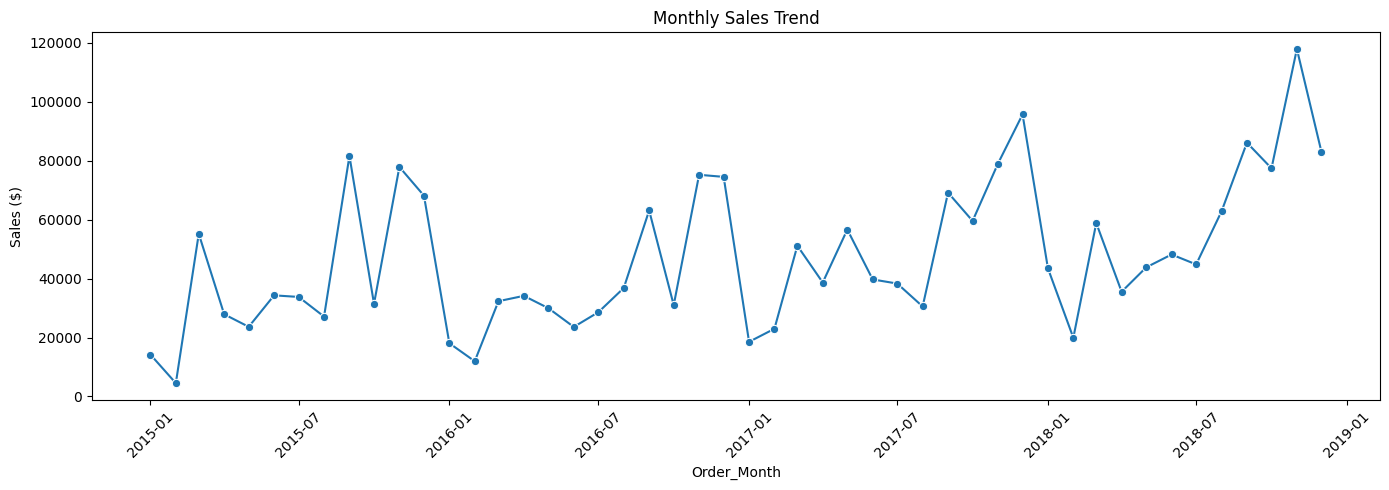

,Order_Month,Sales
36,2018-01-01,43476.4740
37,2018-02-01,19920.9974
38,2018-03-01,58863.4128
39,2018-04-01,35541.9101
40,2018-05-01,43825.9822
41,2018-06-01,48190.7277
42,2018-07-01,44825.1040
43,2018-08-01,62837.8480
44,2018-09-01,86152.8880
45,2018-10-01,77448.1312


In [6]:
# 5) اتجاه المبيعات شهريًا
monthly_sales = (
    df.groupby("Order_Month", as_index=False)["Sales"].sum()
      .sort_values("Order_Month")
)
plt.figure(figsize=(14, 5))
sns.lineplot(data=monthly_sales, x="Order_Month", y="Sales", marker="o")
plt.title("Monthly Sales Trend")
plt.xlabel("Order_Month")
plt.ylabel("Sales ($)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

display(monthly_sales.tail(12))

,Order_Year,Sales,YoY_Change_%
0,2015,479856.2081,NaN
1,2016,459436.0054,-4.255484
2,2017,600192.5500,30.636812
3,2018,722052.0192,20.303396


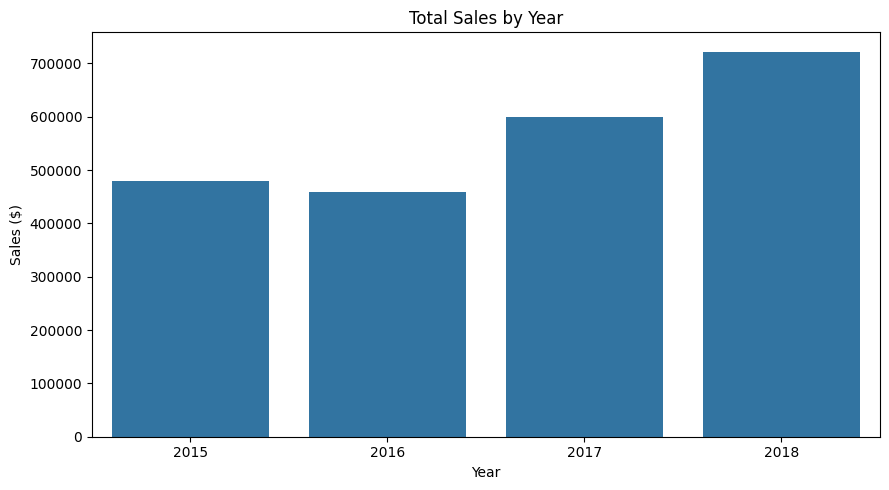

In [7]:
# 6) مقارنة السنوات — هل المبيعات تتحسن أم تتراجع؟
yearly_sales = df.groupby("Order_Year", as_index=False)["Sales"].sum()
yearly_sales["YoY_Change_%"] = yearly_sales["Sales"].pct_change() * 100
display(yearly_sales)

plt.figure(figsize=(9, 5))
sns.barplot(data=yearly_sales, x="Order_Year", y="Sales", errorbar=None)
plt.title("Total Sales by Year")
plt.xlabel("Year")
plt.ylabel("Sales ($)")
plt.tight_layout()
plt.show()

,Region,Sales,Orders
2,South,389151.4590,810
0,Central,492646.9132,1156
1,East,669518.7260,1369
3,West,710219.6845,1587


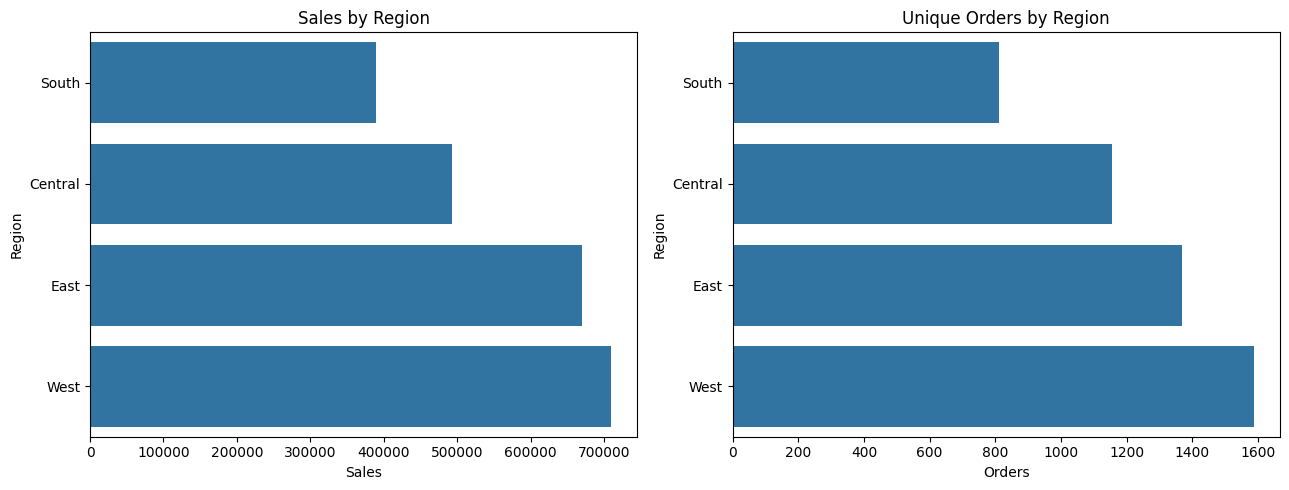

In [8]:
# 7) تحديد المناطق الأضعف بالمبيعات
region_sales = (
    df.groupby("Region", as_index=False)
      .agg(Sales=("Sales", "sum"), Orders=("Order_ID", "nunique"))
      .sort_values("Sales")
)
display(region_sales)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.barplot(data=region_sales, x="Sales", y="Region", ax=axes[0], errorbar=None)
axes[0].set_title("Sales by Region")
sns.barplot(data=region_sales, x="Orders", y="Region", ax=axes[1], errorbar=None)
axes[1].set_title("Unique Orders by Region")
plt.tight_layout()
plt.show()

In [20]:

# 8) الفئات والفئات الفرعية الأقل مبيعًا

# توحيد أسماء الأعمدة
df.columns = (
    df.columns.astype(str)
    .str.strip()
    .str.replace(" ", "_", regex=False)
    .str.replace("-", "_", regex=False)
)

# التأكد من الأعمدة المطلوبة
required = ["Category", "Sub_Category", "Sales", "Order_ID"]
missing = [col for col in required if col not in df.columns]

if missing:
    print("Missing columns:", missing)
    print("Available columns:", df.columns.tolist())
else:
    category_sales = (
        df.groupby("Category", as_index=False)
        .agg(
            Sales=("Sales", "sum"),
            Orders=("Order_ID", "nunique")
        )
        .sort_values("Sales")
    )

    subcat_sales = (
        df.groupby("Sub_Category", as_index=False)
        .agg(
            Sales=("Sales", "sum"),
            Orders=("Order_ID", "nunique")
        )
        .sort_values("Sales")
    )

    display(category_sales)
    display(subcat_sales.head(10))


,Category,Sales,Orders
1,Office Supplies,705422.3340,3676
0,Furniture,728658.5757,1727
2,Technology,827455.8730,1519


,Sub_Category,Sales,Orders
8,Fasteners,3001.9600,212
10,Labels,12347.7260,340
7,Envelopes,16128.0460,243
2,Art,26705.4100,720
15,Supplies,46420.3080,181
12,Paper,76828.3040,1163
9,Furnishings,89212.0180,855
1,Appliances,104618.4030,444
4,Bookcases,113813.1987,222
6,Copiers,146248.0940,66


In [11]:
# 9) المنتجات الأقل والأعلى مبيعًا
product_sales = (
    df.groupby(["Product_ID", "Product_Name"], as_index=False)
      .agg(Sales=("Sales", "sum"), Orders=("Order_ID", "nunique"))
      .sort_values("Sales")
)
print("10 lowest-sales products")
display(product_sales.head(10))
print("10 highest-sales products")
display(product_sales.tail(10).sort_values("Sales", ascending=False))

10 lowest-sales products


,Product_ID,Product_Name,Sales,Orders
427,OFF-AP-10002203,Eureka Disposable Bags for Sanitaire Vibra Gro...,1.624,1
1001,OFF-LA-10003388,Avery 5,5.760,1
1029,OFF-PA-10000048,Xerox 20,6.480,1
875,OFF-EN-10001535,Grip Seal Envelopes,7.072,1
1468,OFF-SU-10003936,Acme Serrated Blade Letter Opener,7.632,1
616,OFF-AR-10003986,Avery Hi-Liter Pen Style Six-Color Fluorescent...,7.700,1
515,OFF-AR-10001149,Avery Hi-Liter Comfort Grip Fluorescent Highli...,7.800,2
1260,OFF-PA-10003919,Xerox 1989,7.968,1
591,OFF-AR-10003477,4009 Highlighters,8.040,1
931,OFF-FA-10001754,Stockwell Gold Paper Clips,8.096,2


10 highest-sales products


,Product_ID,Product_Name,Sales,Orders
1639,TEC-CO-10004722,Canon imageCLASS 2200 Advanced Copier,61599.824,5
787,OFF-BI-10003527,Fellowes PB500 Electric Punch Plastic Comb Bin...,27453.384,10
1668,TEC-MA-10002412,Cisco TelePresence System EX90 Videoconferenci...,22638.480,1
82,FUR-CH-10002024,HON 5400 Series Task Chairs for Big and Tall,21870.576,8
701,OFF-BI-10001359,GBC DocuBind TL300 Electric Binding System,19823.479,11
667,OFF-BI-10000545,GBC Ibimaster 500 Manual ProClick Binding System,19024.500,9
1629,TEC-CO-10001449,Hewlett Packard LaserJet 3310 Copier,18839.686,8
1656,TEC-MA-10001127,HP Designjet T520 Inkjet Large Format Printer ...,18374.895,3
858,OFF-BI-10004995,GBC DocuBind P400 Electric Binding System,17965.068,6
1442,OFF-SU-10000151,High Speed Automatic Electric Letter Opener,17030.312,3


,Order_Month,Sales,Orders,Sales per Order
36,2018-01-01,43476.4740,67,648.902597
37,2018-02-01,19920.9974,52,383.096104
38,2018-03-01,58863.4128,117,503.106092
39,2018-04-01,35541.9101,115,309.060088
40,2018-05-01,43825.9822,116,377.810191
41,2018-06-01,48190.7277,129,373.571533
42,2018-07-01,44825.1040,108,415.047259
43,2018-08-01,62837.8480,109,576.494018
44,2018-09-01,86152.8880,222,388.076072
45,2018-10-01,77448.1312,144,537.834244


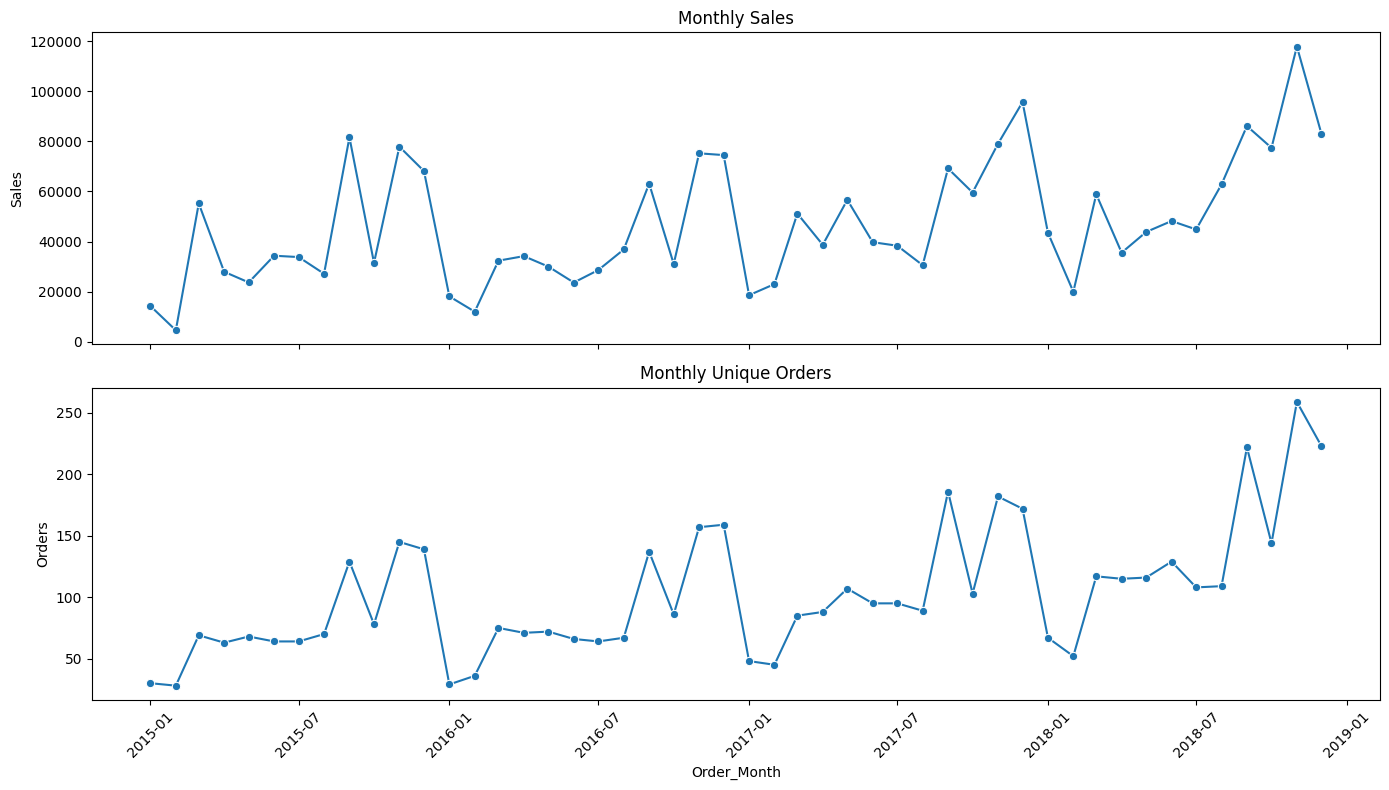

In [12]:
# 10) التمييز بين انخفاض قيمة المبيعات وانخفاض عدد الطلبات
monthly_orders = (
    df.groupby("Order_Month")
      .agg(Sales=("Sales", "sum"), Orders=("Order_ID", "nunique"))
      .reset_index()
)
monthly_orders["Sales per Order"] = monthly_orders["Sales"] / monthly_orders["Orders"]
display(monthly_orders.tail(12))

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
sns.lineplot(data=monthly_orders, x="Order_Month", y="Sales", marker="o", ax=axes[0])
axes[0].set_title("Monthly Sales")
sns.lineplot(data=monthly_orders, x="Order_Month", y="Orders", marker="o", ax=axes[1])
axes[1].set_title("Monthly Unique Orders")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [13]:
# 11) تحديد أشهر الانخفاض مقارنة بالشهر السابق
monthly_orders["Previous_Month_Sales"] = monthly_orders["Sales"].shift(1)
monthly_orders["MoM_Change_%"] = (
    (monthly_orders["Sales"] - monthly_orders["Previous_Month_Sales"])
    / monthly_orders["Previous_Month_Sales"] * 100
)
declines = monthly_orders[monthly_orders["MoM_Change_%"] < 0].sort_values("MoM_Change_%")
display(declines[["Order_Month", "Sales", "Previous_Month_Sales", "MoM_Change_%"]].head(10))

,Order_Month,Sales,Previous_Month_Sales,MoM_Change_%
24,2017-01-01,18542.4910,74543.6012,-75.125308
12,2016-01-01,18066.9576,68167.0585,-73.496058
1,2015-02-01,4519.8920,14205.7070,-68.182562
9,2015-10-01,31453.3930,81623.5268,-61.465286
36,2018-01-01,43476.4740,95739.1210,-54.588601
37,2018-02-01,19920.9974,43476.4740,-54.179823
21,2016-10-01,31011.7375,63133.6060,-50.879192
3,2015-04-01,27906.8550,55205.7970,-49.449412
39,2018-04-01,35541.9101,58863.4128,-39.619692
13,2016-02-01,11951.4110,18066.9576,-33.849344


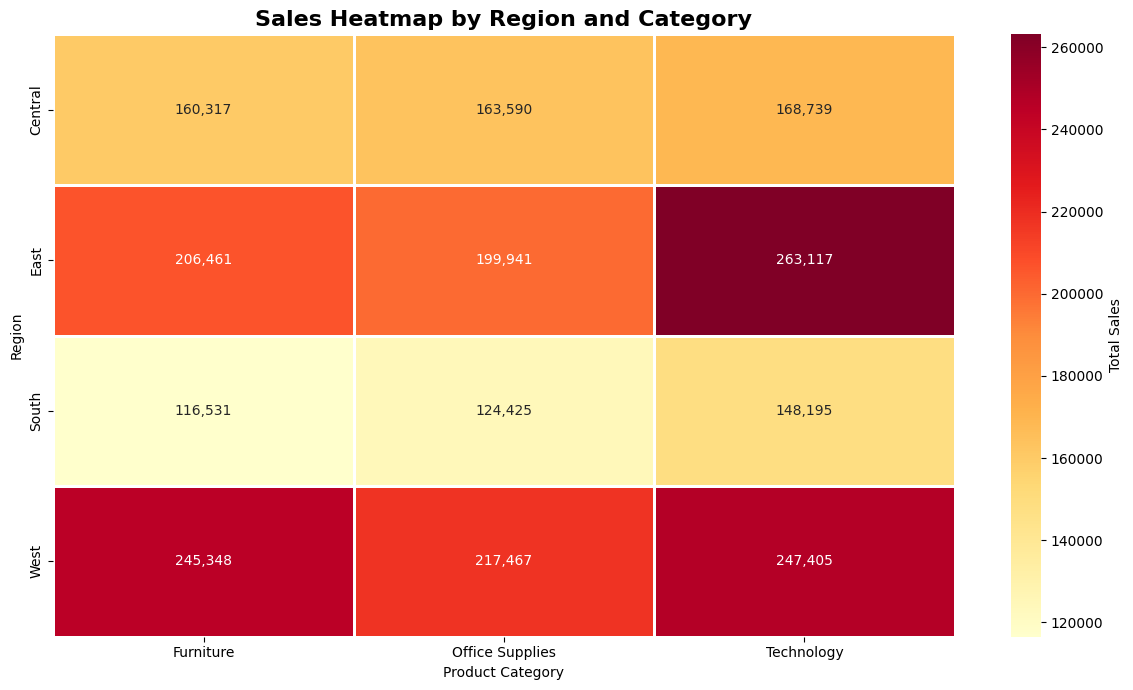

In [14]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# تجهيز البيانات
heatmap_data = df.pivot_table(
    index="Region",
    columns="Category",
    values="Sales",
    aggfunc="sum",
    fill_value=0
)

# رسم الخريطة الحرارية
plt.figure(figsize=(12, 7))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=",.0f",
    cmap="YlOrRd",
    linewidths=1,
    linecolor="white",
    cbar_kws={"label": "Total Sales"}
)

plt.title(
    "Sales Heatmap by Region and Category",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Product Category")
plt.ylabel("Region")

plt.tight_layout()
plt.show()

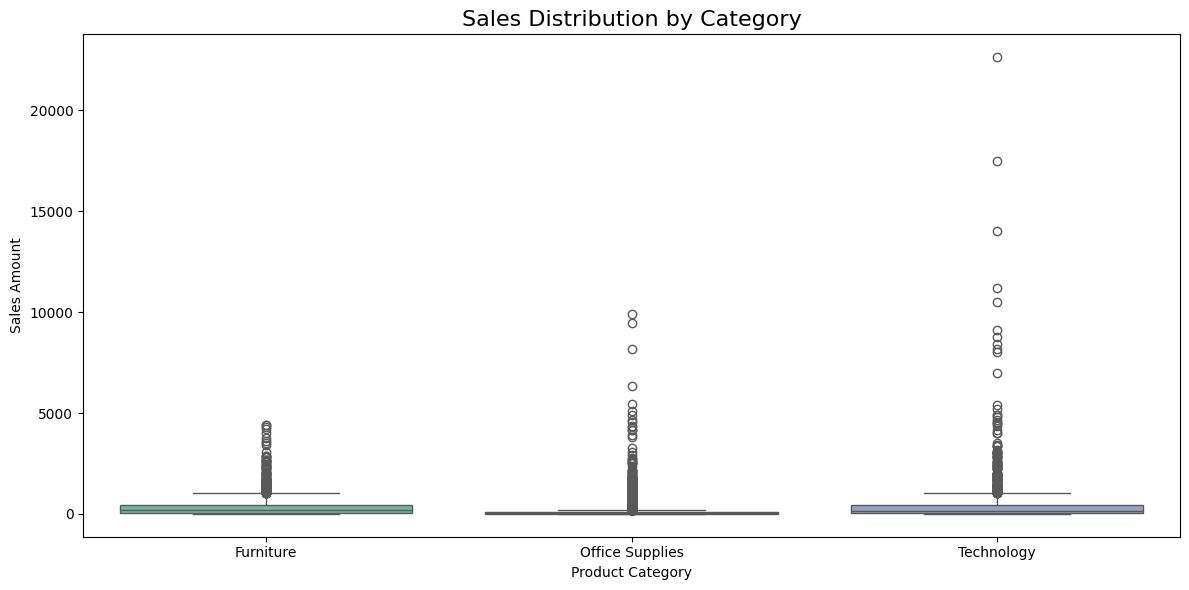

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df,
    x="Category",
    y="Sales",
    palette="Set2",
    hue="Category",
    legend=False
)

plt.title("Sales Distribution by Category", fontsize=16)
plt.xlabel("Product Category")
plt.ylabel("Sales Amount")

plt.tight_layout()
plt.show()

In [21]:

import numpy as np
import pandas as pd

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.metrics import (
    accuracy_score, precision_score, f1_score,
    confusion_matrix, classification_report
)

# تجهيز المبيعات الشهرية من بيانات الطلبات
df.columns = (
    df.columns.astype(str)
    .str.strip()
    .str.replace(" ", "_", regex=False)
    .str.replace("-", "_", regex=False)
)

df["Order_Date"] = pd.to_datetime(
    df["Order_Date"], errors="coerce", dayfirst=True
)

sales_data = df.dropna(subset=["Order_Date"]).copy()
sales_data["Order_Month"] = (
    sales_data["Order_Date"].dt.to_period("M").dt.to_timestamp()
)

monthly_sales = (
    sales_data.groupby("Order_Month", as_index=False)["Sales"]
    .sum()
    .sort_values("Order_Month")
)

# إنشاء الخصائص الزمنية
monthly = (
    monthly_sales.set_index("Order_Month")["Sales"]
    .asfreq("MS", fill_value=0)
    .to_frame()
)

monthly["Month"] = monthly.index.month
monthly["Month_Number"] = np.arange(len(monthly))

for lag in [1, 2, 3, 12]:
    monthly[f"Lag_{lag}"] = monthly["Sales"].shift(lag)

monthly["Rolling_Mean_3"] = monthly["Sales"].shift(1).rolling(3).mean()
monthly["Rolling_Mean_6"] = monthly["Sales"].shift(1).rolling(6).mean()

monthly["Sales_Growth"] = (
    monthly["Sales"].pct_change(fill_method=None)
    .replace([np.inf, -np.inf], np.nan)
)

monthly["Next_Sales"] = monthly["Sales"].shift(-1)
monthly = monthly.dropna().copy()

monthly["Target"] = (
    monthly["Next_Sales"] > monthly["Sales"]
).astype(int)

features = [
    "Month", "Month_Number", "Sales",
    "Lag_1", "Lag_2", "Lag_3", "Lag_12",
    "Rolling_Mean_3", "Rolling_Mean_6",
    "Sales_Growth"
]

X = monthly[features]
y = monthly["Target"]

split = int(len(monthly) * 0.8)

X_train, X_test = X.iloc[:split], X.iloc[split:]
y_train, y_test = y.iloc[:split], y.iloc[split:]

print("Total Months:", len(monthly))
print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))
print("Training Target Counts:", y_train.value_counts().to_dict())

if len(X_train) < 10 or len(X_test) < 3:
    print("Warning: Too few observations for reliable evaluation.")


Total Months: 35
Training Samples: 28
Testing Samples: 7
Training Target Counts: {0: 14, 1: 14}


In [22]:
models = {
 "Logistic Regression": (
    make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, random_state=42)),
    {"logisticregression__C":[0.01,0.1,1,10], "logisticregression__class_weight":[None,"balanced"]}),
 "Random Forest": (
    RandomForestClassifier(random_state=42),
    {"n_estimators":[100,200], "max_depth":[2,4,None], "min_samples_leaf":[1,2,3], "class_weight":[None,"balanced"]})
}
# Ensure each training fold contains both classes for Logistic Regression
possible_splits = []
for n_splits in [3,2]:
    cv = TimeSeriesSplit(n_splits=n_splits)
    if all(y_train.iloc[tr].nunique()==2 for tr,_ in cv.split(X_train)):
        possible_splits.append(cv)
cv = possible_splits[0] if possible_splits else None
if y_train.nunique() < 2:
    raise ValueError("Training set contains only one class; cannot train Logistic Regression")
results, predictions_by_model, trained_models = [], {}, {}
for name, (model, params) in models.items():
    print("Training:", name)
    if cv is not None:
        grid = GridSearchCV(model, params, cv=cv, scoring="f1", n_jobs=-1, error_score=np.nan)
        grid.fit(X_train, y_train)
        fitted = grid.best_estimator_
        print("Best Parameters:", grid.best_params_)
    else:
        print("Not enough balanced time folds for tuning; using base model")
        fitted = model.fit(X_train, y_train)
    trained_models[name] = fitted
    prediction = fitted.predict(X_test)
    predictions_by_model[name] = prediction
    results.append({"Model":name,
        "Accuracy":accuracy_score(y_test,prediction),
        "Precision":precision_score(y_test,prediction,zero_division=0),
        "F1_Score":f1_score(y_test,prediction,zero_division=0)})
results_df = pd.DataFrame(results).sort_values(["F1_Score","Accuracy"], ascending=False).reset_index(drop=True)
display(results_df.style.format({"Accuracy":"{:.2%}","Precision":"{:.2%}","F1_Score":"{:.2%}"}))
best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]
print("Best Model on held-out test:", best_model_name)
print("Note: Small test size; model rankings are uncertain.")

Training: Logistic Regression
Best Parameters: {'logisticregression__C': 10, 'logisticregression__class_weight': None}
Training: Random Forest
Best Parameters: {'class_weight': None, 'max_depth': 2, 'min_samples_leaf': 3, 'n_estimators': 100}


,Model,Accuracy,Precision,F1_Score
0,Logistic Regression,57.14%,66.67%,57.14%
1,Random Forest,42.86%,0.00%,0.00%


Best Model on held-out test: Logistic Regression
Note: Small test size; model rankings are uncertain.


              precision    recall  f1-score   support

           0       0.50      0.67      0.57         3
           1       0.67      0.50      0.57         4

    accuracy                           0.57         7
   macro avg       0.58      0.58      0.57         7
weighted avg       0.60      0.57      0.57         7



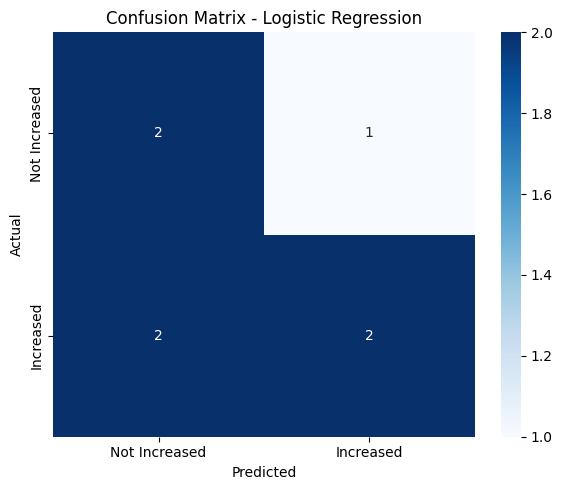

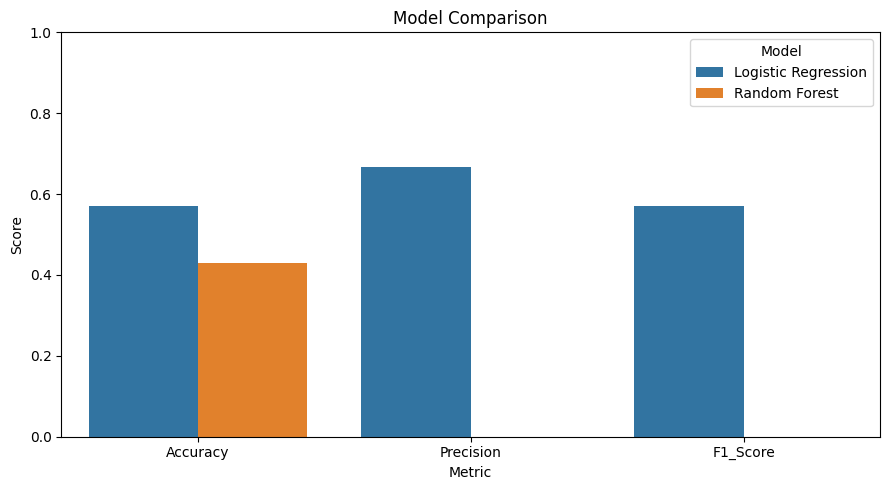

,Actual,Predicted
Order_Month,,
2018-05-01,1,1
2018-06-01,0,1
2018-07-01,1,1
2018-08-01,1,0
2018-09-01,0,0
2018-10-01,1,0
2018-11-01,0,0


In [23]:
best_predictions = predictions_by_model[best_model_name]
print(classification_report(y_test, best_predictions, zero_division=0))
cm = confusion_matrix(y_test, best_predictions, labels=[0,1])
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["Not Increased","Increased"], yticklabels=["Not Increased","Increased"])
plt.title("Confusion Matrix - " + best_model_name); plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.tight_layout(); plt.show()
plot_data = results_df.melt(id_vars="Model", value_vars=["Accuracy","Precision","F1_Score"], var_name="Metric", value_name="Score")
plt.figure(figsize=(9,5)); sns.barplot(data=plot_data, x="Metric", y="Score", hue="Model"); plt.ylim(0,1); plt.title("Model Comparison"); plt.tight_layout(); plt.show()
comparison = pd.DataFrame({"Actual":y_test.values, "Predicted":best_predictions}, index=X_test.index)
display(comparison)

In [24]:
# Retrain selected configuration on all labeled historical months
best_model.fit(X, y)
if len(full_monthly) < 13:
    raise ValueError("Need at least 13 months of history")
prev = full_monthly["Sales"].iloc[-2]
latest_features = pd.DataFrame([{
    "Month":full_monthly.index[-1].month,
    "Month_Number":len(full_monthly)-1,
    "Sales":full_monthly["Sales"].iloc[-1],
    "Lag_1":prev,
    "Lag_2":full_monthly["Sales"].iloc[-3],
    "Lag_3":full_monthly["Sales"].iloc[-4],
    "Lag_12":full_monthly["Sales"].iloc[-13],
    "Rolling_Mean_3":full_monthly["Sales"].iloc[-4:-1].mean(),
    "Rolling_Mean_6":full_monthly["Sales"].iloc[-7:-1].mean(),
    "Sales_Growth":(full_monthly["Sales"].iloc[-1]/prev - 1) if prev != 0 else 0
}])[features]
next_prediction = int(best_model.predict(latest_features)[0])
forecast_month = full_monthly.index[-1] + pd.DateOffset(months=1)
print("Forecast Month:", forecast_month.strftime("%Y-%m"))
print("Predicted Direction:", "INCREASE" if next_prediction else "DECREASE OR SAME")
print("This forecast follows the last month in the historical dataset, not necessarily the current calendar month.")

Forecast Month: 2019-01
Predicted Direction: INCREASE
This forecast follows the last month in the historical dataset, not necessarily the current calendar month.


In [28]:

# ==========================================
# Evaluate Random Forest Regressor
# ==========================================

import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# تجهيز البيانات الشهرية
sales = (
    monthly_sales.copy()
    .sort_values("Order_Month")
    .set_index("Order_Month")["Sales"]
    .asfreq("MS")
)

# إنشاء خصائص من الأشهر السابقة فقط
training_data = pd.DataFrame(index=sales.index)

training_data["Sales"] = sales
training_data["Month"] = sales.index.month
training_data["Month_Number"] = np.arange(len(sales))

for lag in [1, 2, 3, 12]:
    training_data[f"Lag_{lag}"] = sales.shift(lag)

training_data["Rolling_Mean_3"] = (
    sales.shift(1).rolling(3).mean()
)

training_data["Rolling_Mean_6"] = (
    sales.shift(1).rolling(6).mean()
)

training_data = training_data.dropna().copy()

features = [
    "Month",
    "Month_Number",
    "Lag_1",
    "Lag_2",
    "Lag_3",
    "Lag_12",
    "Rolling_Mean_3",
    "Rolling_Mean_6"
]

X = training_data[features]
y = training_data["Sales"]

# تقسيم زمني 80% تدريب و20% اختبار
split = int(len(X) * 0.8)

X_train = X.iloc[:split]
X_test = X.iloc[split:]
y_train = y.iloc[:split]
y_test = y.iloc[split:]

print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))

if len(X_train) < 10 or len(X_test) < 3:
    print("Not enough observations for reliable evaluation.")
else:
    # تدريب النموذج
    evaluation_model = RandomForestRegressor(
        n_estimators=300,
        max_depth=5,
        min_samples_leaf=2,
        random_state=42
    )

    evaluation_model.fit(X_train, y_train)

    # التنبؤ
    y_pred = evaluation_model.predict(X_test)

    # حساب مؤشرات التقييم
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    print("\nRandom Forest Regressor Evaluation")
    print("---------------------------------")
    print(f"MAE: {mae:,.2f}")
    print(f"RMSE: {rmse:,.2f}")
    print(f"R² Score: {r2:.4f}")

    # مقارنة المبيعات الفعلية والمتوقعة
    evaluation_results = pd.DataFrame({
        "Actual_Sales": y_test,
        "Predicted_Sales": y_pred
    }, index=y_test.index)

    display(evaluation_results.round(2))


Training Samples: 28
Testing Samples: 8

Random Forest Regressor Evaluation
---------------------------------
MAE: 13,089.45
RMSE: 16,942.37
R² Score: 0.5038


,Actual_Sales,Predicted_Sales
Order_Month,,
2018-05-01,43825.98,51518.36
2018-06-01,48190.73,39454.57
2018-07-01,44825.10,39041.66
2018-08-01,62837.85,40261.81
2018-09-01,86152.89,73622.16
2018-10-01,77448.13,69812.04
2018-11-01,117938.16,80565.72
2018-12-01,83030.39,80642.04


Training Samples: 28
Testing Samples: 8


,Model,MAE,RMSE,R2
0,Linear Regression,"12,716.89","15,612.65",0.5786
1,Random Forest Regressor,"13,026.25","16,815.00",0.5112


Best Regression Model: Linear Regression


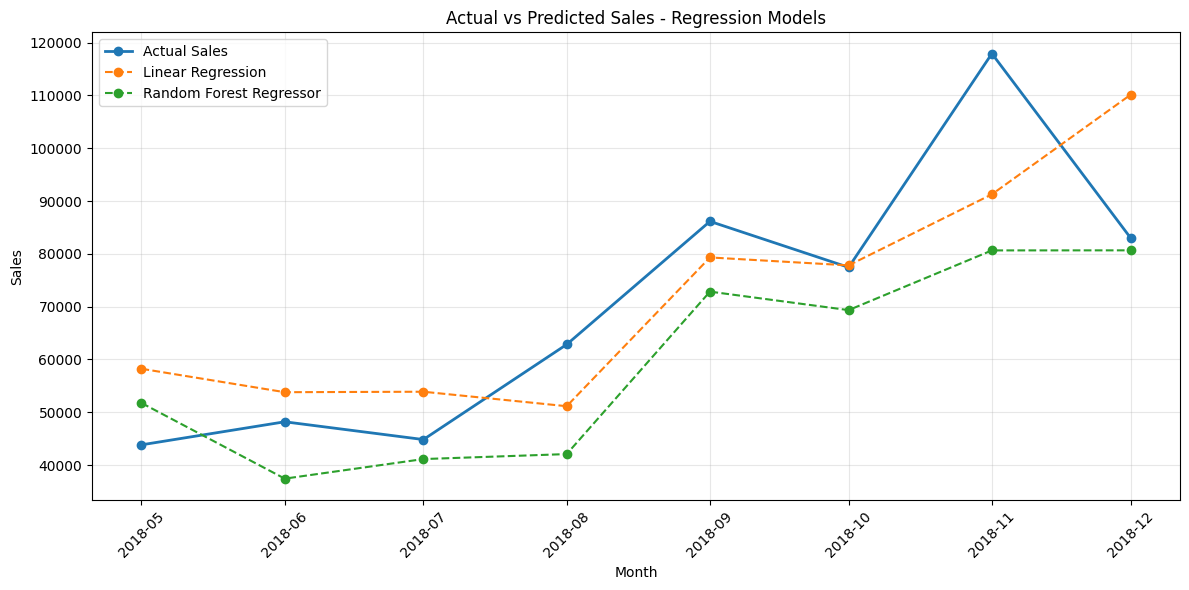

In [30]:

# ==========================================
# Linear Regression vs Random Forest Regressor
# ==========================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# إعداد البيانات
reg_features = [
    "Month",
    "Month_Number",
    "Lag_1",
    "Lag_2",
    "Lag_3",
    "Lag_12"
]

X = training_data[reg_features].copy()
y = training_data["Sales"].copy()

# تقسيم البيانات حسب الترتيب الزمني
split = int(len(X) * 0.8)

X_train = X.iloc[:split]
X_test = X.iloc[split:]

y_train = y.iloc[:split]
y_test = y.iloc[split:]

print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))

if len(X_train) < 10 or len(X_test) < 3:
    print("Not enough observations for reliable model comparison.")

else:
    # تعريف النماذج
    regression_models = {
        "Linear Regression": LinearRegression(),

        "Random Forest Regressor": RandomForestRegressor(
            n_estimators=300,
            max_depth=5,
            min_samples_leaf=2,
            random_state=42
        )
    }

    results = []
    predictions = {}

    # تدريب وتقييم النماذج
    for name, model in regression_models.items():

        model.fit(X_train, y_train)

        y_pred = model.predict(X_test)
        predictions[name] = y_pred

        results.append({
            "Model": name,
            "MAE": mean_absolute_error(y_test, y_pred),
            "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
            "R2": r2_score(y_test, y_pred)
        })

    # جدول مقارنة الأداء
    regression_results = pd.DataFrame(results)

    display(
        regression_results.style.format({
            "MAE": "{:,.2f}",
            "RMSE": "{:,.2f}",
            "R2": "{:.4f}"
        })
    )

    # أفضل نموذج حسب MAE
    best_regression = regression_results.loc[
        regression_results["MAE"].idxmin(), "Model"
    ]

    print("Best Regression Model:", best_regression)

    # رسم المبيعات الفعلية والمتوقعة
    plt.figure(figsize=(12, 6))

    plt.plot(
        y_test.index,
        y_test.values,
        marker="o",
        linewidth=2,
        label="Actual Sales"
    )

    for name, y_pred in predictions.items():
        plt.plot(
            y_test.index,
            y_pred,
            marker="o",
            linestyle="--",
            label=name
        )

    plt.title("Actual vs Predicted Sales - Regression Models")
    plt.xlabel("Month")
    plt.ylabel("Sales")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()


Historical Data:


,Sales
Order_Month,
2015-01-01,14205.707
2015-02-01,4519.892
2015-03-01,55205.797
2015-04-01,27906.855
2015-05-01,23644.303


Last Historical Month: 2018-12

LINEAR REGRESSION EVALUATION
MAE: 12,716.89
RMSE: 15,612.65
R2 Score: 0.5786

Linear Regression Model Trained Successfully!

MONTHLY SALES FORECAST - 2027


,Month,Predicted_Sales
96,January,"203,281.89"
97,February,"205,548.83"
98,March,"209,152.60"
99,April,"210,432.67"
100,May,"216,691.49"
101,June,"223,468.72"
102,July,"230,344.41"
103,August,"237,863.26"
104,September,"245,541.67"
105,October,"253,205.58"



2027 FORECAST SUMMARY
Total Predicted Sales: 2,765,447.42
Average Monthly Sales: 230,453.95
Highest Month: December (268,827.09)
Lowest Month: January (203,281.89)


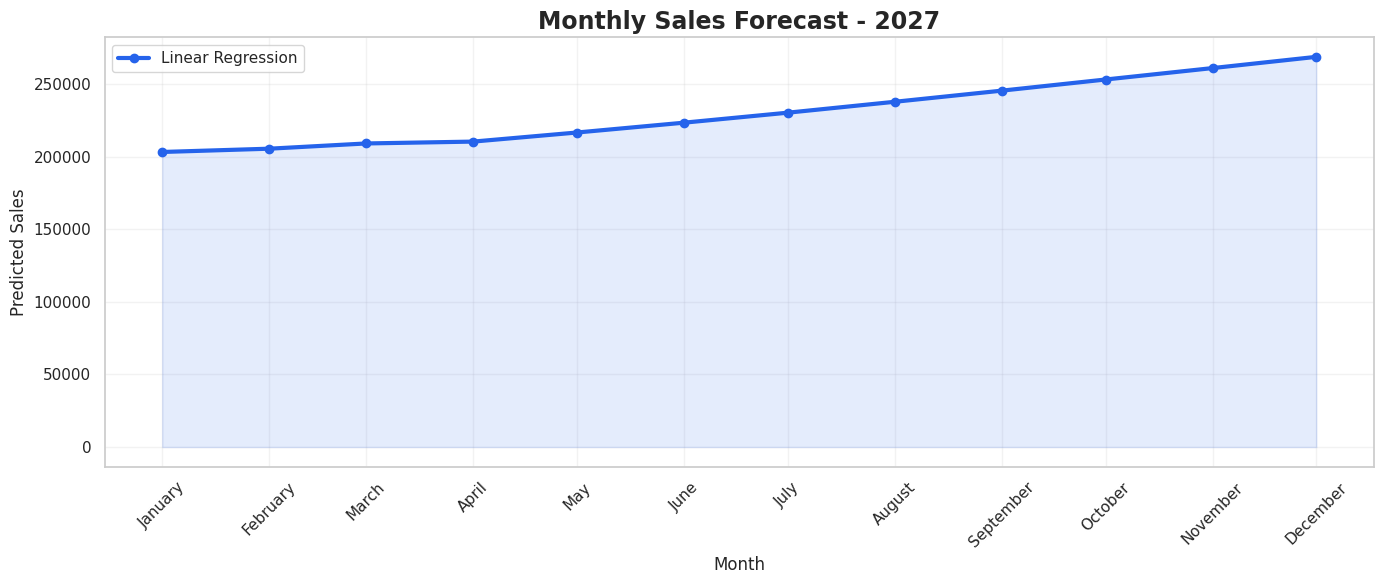

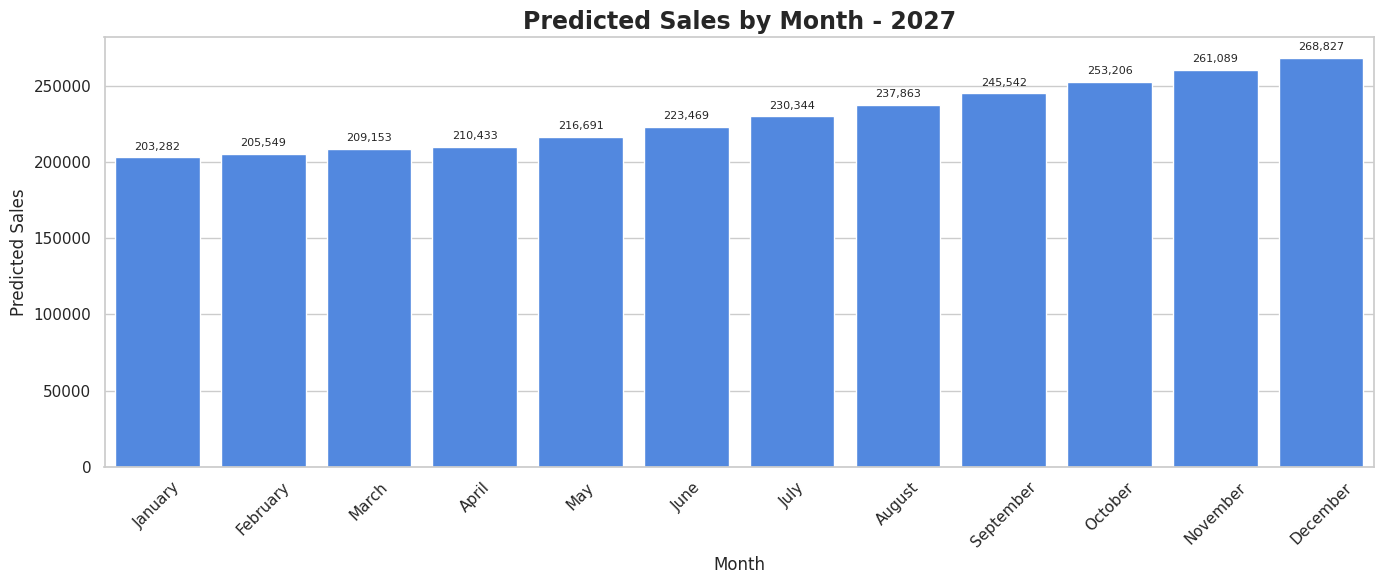

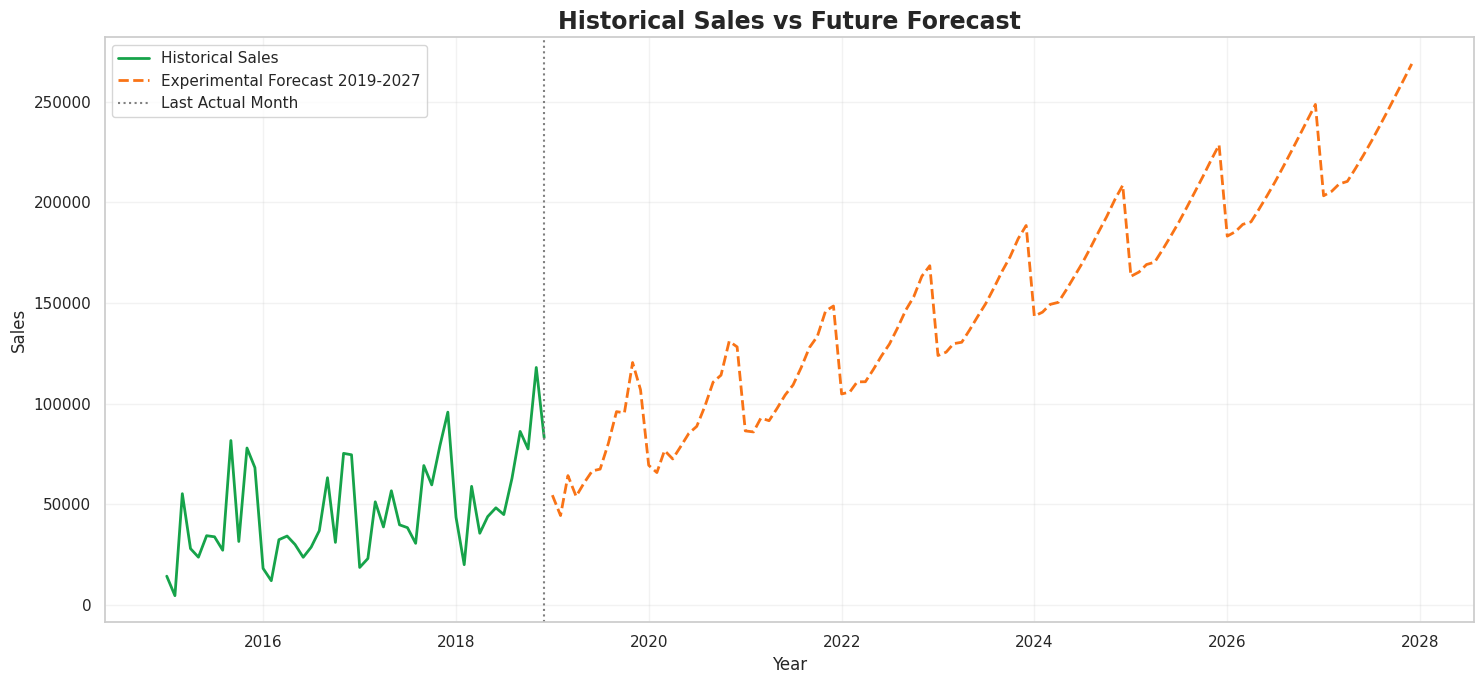

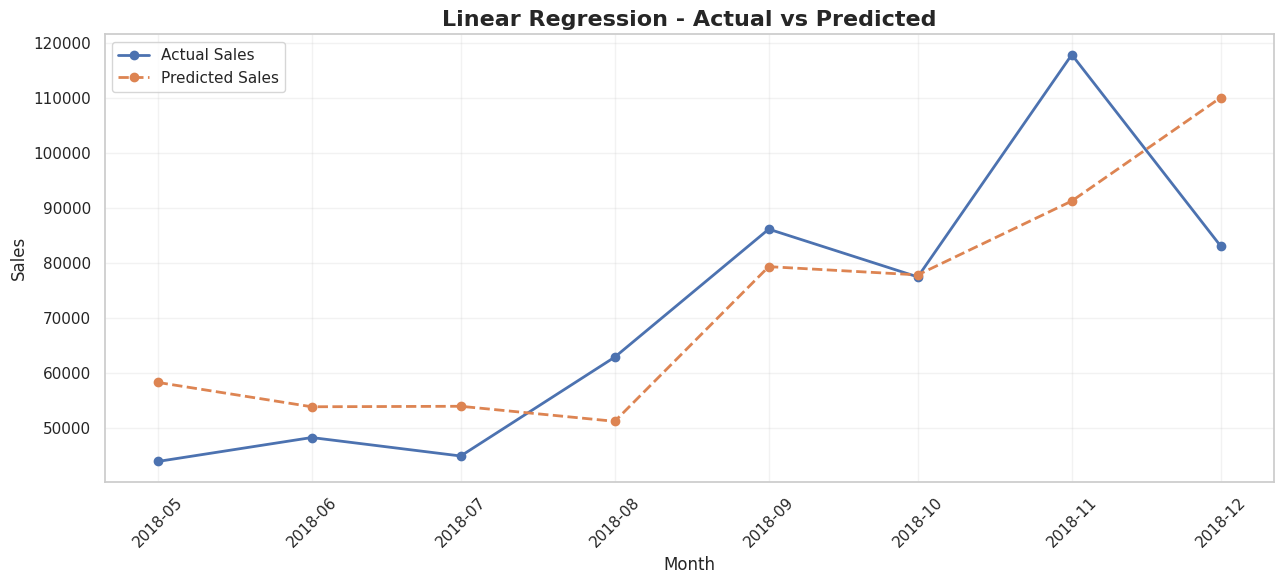


FORECAST COMPLETED SUCCESSFULLY!
Saved File: Sales_Forecast_2027.csv
Charts Generated: 4
Forecast Year: 2027


In [31]:
# ============================================================
# SALES FORECASTING DASHBOARD - 2027
# Model: Linear Regression
# Historical Data: 2015 - 2018
# ============================================================

# 1. IMPORT LIBRARIES
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from IPython.display import display

%matplotlib inline

sns.set_theme(style="whitegrid")


# ============================================================
# 2. LOAD AND PREPARE DATA
# ============================================================

# Use existing monthly_sales or create it from df

if "monthly_sales" not in globals():

    data = df.copy()

    data["Order_Date"] = pd.to_datetime(
        data["Order_Date"]
    )

    monthly_sales = (
        data.groupby(
            pd.Grouper(
                key="Order_Date",
                freq="MS"
            )
        )["Sales"]
        .sum()
        .reset_index()
        .rename(
            columns={"Order_Date": "Order_Month"}
        )
    )

monthly_sales["Order_Month"] = pd.to_datetime(
    monthly_sales["Order_Month"]
)

history = (
    monthly_sales
    .set_index("Order_Month")["Sales"]
    .sort_index()
    .resample("MS")
    .sum()
    .to_frame()
)

print("Historical Data:")
display(history.head())

print(
    "Last Historical Month:",
    history.index.max().strftime("%Y-%m")
)


# ============================================================
# 3. FEATURE ENGINEERING
# ============================================================

history["Month"] = history.index.month

history["Time_Index"] = np.arange(
    len(history)
)

history["Lag_1"] = history["Sales"].shift(1)
history["Lag_2"] = history["Sales"].shift(2)
history["Lag_3"] = history["Sales"].shift(3)
history["Lag_12"] = history["Sales"].shift(12)

training_data_2027 = history.dropna().copy()

features_2027 = [
    "Month",
    "Time_Index",
    "Lag_1",
    "Lag_2",
    "Lag_3",
    "Lag_12"
]

X = training_data_2027[features_2027]
y = training_data_2027["Sales"]


# ============================================================
# 4. TRAIN AND EVALUATE MODEL
# ============================================================

split = int(len(X) * 0.8)

X_train = X.iloc[:split]
X_test = X.iloc[split:]

y_train = y.iloc[:split]
y_test = y.iloc[split:]

evaluation_model = LinearRegression()

evaluation_model.fit(
    X_train,
    y_train
)

y_pred = evaluation_model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)

rmse = np.sqrt(
    mean_squared_error(y_test, y_pred)
)

r2 = r2_score(y_test, y_pred)

print("\n================================")
print("LINEAR REGRESSION EVALUATION")
print("================================")

print(f"MAE: {mae:,.2f}")
print(f"RMSE: {rmse:,.2f}")
print(f"R2 Score: {r2:.4f}")


# ============================================================
# 5. TRAIN FINAL MODEL
# ============================================================

linear_model_2027 = LinearRegression()

linear_model_2027.fit(X, y)

print("\nLinear Regression Model Trained Successfully!")


# ============================================================
# 6. FORECAST UNTIL DECEMBER 2027
# ============================================================

sales_series = history["Sales"].copy()

future_dates = pd.date_range(
    start=history.index[-1] + pd.offsets.MonthBegin(1),
    end="2027-12-01",
    freq="MS"
)

predictions_2027 = []

for date in future_dates:

    next_features = pd.DataFrame([{
        "Month": date.month,
        "Time_Index": len(sales_series),
        "Lag_1": sales_series.iloc[-1],
        "Lag_2": sales_series.iloc[-2],
        "Lag_3": sales_series.iloc[-3],
        "Lag_12": sales_series.iloc[-12]
    }])

    predicted_sales = linear_model_2027.predict(
        next_features[features_2027]
    )[0]

    predicted_sales = max(
        0,
        predicted_sales
    )

    sales_series.loc[date] = predicted_sales

    predictions_2027.append({
        "Date": date,
        "Predicted_Sales": predicted_sales
    })

forecast_all_2027 = pd.DataFrame(
    predictions_2027
)


# ============================================================
# 7. FILTER YEAR 2027
# ============================================================

forecast_2027_linear = forecast_all_2027[
    forecast_all_2027["Date"].dt.year == 2027
].copy()

forecast_2027_linear["Month"] = (
    forecast_2027_linear["Date"].dt.strftime("%B")
)

print("\n================================")
print("MONTHLY SALES FORECAST - 2027")
print("================================")

display(
    forecast_2027_linear[
        ["Month", "Predicted_Sales"]
    ].style.format({
        "Predicted_Sales": "{:,.2f}"
    })
)


# ============================================================
# 8. FORECAST SUMMARY
# ============================================================

total_2027 = forecast_2027_linear[
    "Predicted_Sales"
].sum()

average_2027 = forecast_2027_linear[
    "Predicted_Sales"
].mean()

highest = forecast_2027_linear.loc[
    forecast_2027_linear["Predicted_Sales"].idxmax()
]

lowest = forecast_2027_linear.loc[
    forecast_2027_linear["Predicted_Sales"].idxmin()
]

print("\n================================")
print("2027 FORECAST SUMMARY")
print("================================")

print(f"Total Predicted Sales: {total_2027:,.2f}")
print(f"Average Monthly Sales: {average_2027:,.2f}")

print(
    f"Highest Month: {highest['Month']} "
    f"({highest['Predicted_Sales']:,.2f})"
)

print(
    f"Lowest Month: {lowest['Month']} "
    f"({lowest['Predicted_Sales']:,.2f})"
)


# ============================================================
# 9. CHART 1 - MONTHLY FORECAST
# ============================================================

plt.figure(figsize=(14, 6))

plt.plot(
    forecast_2027_linear["Date"],
    forecast_2027_linear["Predicted_Sales"],
    marker="o",
    linewidth=3,
    color="#2563EB",
    label="Linear Regression"
)

plt.fill_between(
    forecast_2027_linear["Date"],
    forecast_2027_linear["Predicted_Sales"],
    alpha=0.12,
    color="#2563EB"
)

plt.title(
    "Monthly Sales Forecast - 2027",
    fontsize=17,
    fontweight="bold"
)

plt.xlabel("Month")
plt.ylabel("Predicted Sales")

plt.xticks(
    forecast_2027_linear["Date"],
    forecast_2027_linear["Month"],
    rotation=45
)

plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


# ============================================================
# 10. CHART 2 - MONTHLY SALES BAR CHART
# ============================================================

plt.figure(figsize=(14, 6))

ax = sns.barplot(
    data=forecast_2027_linear,
    x="Month",
    y="Predicted_Sales",
    color="#3B82F6"
)

plt.title(
    "Predicted Sales by Month - 2027",
    fontsize=17,
    fontweight="bold"
)

plt.xlabel("Month")
plt.ylabel("Predicted Sales")

plt.xticks(rotation=45)

for bar in ax.patches:

    height = bar.get_height()

    ax.annotate(
        f"{height:,.0f}",
        (
            bar.get_x() + bar.get_width() / 2,
            height
        ),
        ha="center",
        va="bottom",
        fontsize=8,
        xytext=(0, 4),
        textcoords="offset points"
    )

plt.tight_layout()
plt.show()


# ============================================================
# 11. CHART 3 - HISTORICAL VS FORECAST
# ============================================================

plt.figure(figsize=(15, 7))

plt.plot(
    history.index,
    history["Sales"],
    label="Historical Sales",
    linewidth=2,
    color="#16A34A"
)

plt.plot(
    forecast_all_2027["Date"],
    forecast_all_2027["Predicted_Sales"],
    label="Experimental Forecast 2019-2027",
    linewidth=2,
    linestyle="--",
    color="#F97316"
)

plt.axvline(
    history.index[-1],
    color="gray",
    linestyle=":",
    label="Last Actual Month"
)

plt.title(
    "Historical Sales vs Future Forecast",
    fontsize=17,
    fontweight="bold"
)

plt.xlabel("Year")
plt.ylabel("Sales")

plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


# ============================================================
# 12. CHART 4 - ACTUAL VS PREDICTED (TEST)
# ============================================================

plt.figure(figsize=(13, 6))

plt.plot(
    y_test.index,
    y_test.values,
    marker="o",
    linewidth=2,
    label="Actual Sales"
)

plt.plot(
    y_test.index,
    y_pred,
    marker="o",
    linestyle="--",
    linewidth=2,
    label="Predicted Sales"
)

plt.title(
    "Linear Regression - Actual vs Predicted",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Month")
plt.ylabel("Sales")

plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


# ============================================================
# 13. EXPORT RESULTS
# ============================================================

forecast_2027_linear[
    ["Date", "Month", "Predicted_Sales"]
].to_csv(
    "Sales_Forecast_2027.csv",
    index=False
)

print("\n================================")
print("FORECAST COMPLETED SUCCESSFULLY!")
print("================================")

print("Saved File: Sales_Forecast_2027.csv")
print("Charts Generated: 4")
print("Forecast Year: 2027")

In [32]:
import os
print(os.getcwd())

/content


In [33]:
# Export cleaned sales data
df.to_csv("Sales_Data_Cleaned.csv", index=False)

# Export monthly sales
monthly_sales.to_csv("Monthly_Sales.csv", index=False)

# Export 2027 predictions
forecast_2027_linear.to_csv(
    "Sales_Forecast_2027.csv",
    index=False
)

print("All files exported successfully!")

All files exported successfully!


In [34]:
import joblib

joblib.dump(model, "trained_model.pkl")

['trained_model.pkl']